# Clase 10 — Analizando el catálogo de Netflix

En este ejercicio asumirás el rol de un **Data Analyst** dentro de Netflix. El equipo de negocio quiere entender mejor cómo está distribuido el catálogo de la plataforma para tomar decisiones sobre futuras inversiones en contenido.

Para ello deberás utilizar las herramientas aprendidas en esta clase:

- `groupby()`
- funciones de agregación
- `agg()`
- `pivot_table()`
- `unstack()`
- gráficos con Pandas y Matplotlib

> No utilices bucles (`for`) para resolver los ejercicios.


## Parte 1: Exploración del dataset

Antes de comenzar el análisis responde:

1. Carga el dataset.
2. Muestra las primeras filas.
3. ¿Cuántas filas y columnas posee? Posee 8807 filas, 12 columnas
4. ¿Qué tipo de dato tiene cada columna? Tienen datos de tipo texto, numeros enteros
5. ¿Existen valores nulos? Si, contiene valores nulos en director, country, cast, date_added, rating, duration
6. ¿Qué columnas presentan mayor cantidad de valores faltantes? De mayor a menor es Director, country, cast son los que mayores datos faltantes representan

In [55]:
import pandas as pd

df=pd.read_csv("netflix_data.csv")

df.head()




,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [56]:
df.shape

#Columnas que posee

(8807, 12)

In [57]:
df.info()

#Tipos de datos

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [58]:
df.isnull().sum()

#Valores nulos

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [ ]:
df.isnull().sum().sort_values(ascending=False)

#Ordene los nulos de manera descendente

director        2634
country          831
cast             825
date_added        10
rating             4
duration           3
show_id            0
type               0
title              0
release_year       0
listed_in          0
description        0
dtype: int64

## Parte 2: Agrupaciones

### Ejercicio 1 - ¿Cuántos títulos existen por país?

Ordena el resultado de mayor a menor.


In [60]:
df.groupby(["country"])["title"].count().sort_values(ascending=False)

country
United States          2818
India                   972
United Kingdom          419
Japan                   245
South Korea             199
                       ... 
Australia, Iraq           1
Venezuela                 1
Venezuela, Colombia       1
West Germany              1
, South Korea             1
Name: title, Length: 748, dtype: int64

### Ejercicio 2 - ¿Cuántas películas y cuántas series tiene Netflix?

Tenemos 6131 peliculas y 2676 series

In [181]:
df.groupby('type')['show_id'].count()

type
Movie      6131
TV Show    2676
Name: show_id, dtype: int64

### Ejercicio 3 - ¿Cuántos títulos fueron lanzados cada año?

Ordena el resultado cronológicamente.


In [54]:
df.groupby('release_year')['show_id'].count().sort_index(ascending=True)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: show_id, Length: 74, dtype: int64

### Ejercicio 4 - ¿Cuál es la clasificación por edades más frecuente?

Por ejemplo:

- TV-MA
- TV-14
- PG
- R

La clasificacion por edades mas frecuentes son

- TV-MA 3207
- TV-14 2160

In [67]:
df.groupby('rating')['show_id'].count().sort_values(ascending=False)

#La clasificacion por edades mas frecuentes son
#- TV-MA 3207
#- TV-14 2160

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
66 min         1
84 min         1
74 min         1
Name: show_id, dtype: int64

### Ejercicio 5 - Obtén para cada tipo de contenido (Movie y TV Show):

- cantidad de títulos - 8807 titulos en total
- año promedio de lanzamiento - Año 2014
- año más reciente - Año 2021
- año más antiguo - Año 1925

> Utiliza **agg()**.

In [ ]:
df.agg({'show_id': 'count', 'release_year': ['mean', 'max', 'min']}).round()





# 8807 titulos en total
# Año 2014 es el promedio
# Año 2021 es el maximo
# Año 1925 es el minimo


,show_id,release_year
count,8807.0,NaN
mean,NaN,2014.0
max,NaN,2021.0
min,NaN,1925.0


## Parte 3: Agrupaciones múltiples

### Ejercicio 6 - Obtén la cantidad de títulos para cada combinación.

Agrupa por:

- país
- tipo de contenido

In [100]:
df.groupby(['country', 'type'])['show_id'].count().sort_values(ascending=False)



country                            type   
United States                      Movie      2058
India                              Movie       893
United States                      TV Show     760
United Kingdom                     TV Show     213
                                   Movie       206
                                              ... 
Argentina, Uruguay, Spain, France  Movie         1
Argentina, Uruguay, Serbia         Movie         1
Argentina, United States, Mexico   TV Show       1
Argentina, United States           Movie         1
Argentina, Spain                   TV Show       1
Name: show_id, Length: 847, dtype: int64

### Ejercicio 7 - Convierte el resultado anterior en una tabla donde:

- las filas sean los países
- las columnas sean Movie y TV Show

> Utiliza **unstack()**.

In [103]:
df.groupby(["country", "type"])["show_id"].count().unstack()

type,Movie,TV Show
country,,
", France, Algeria",1.0,NaN
", South Korea",NaN,1.0
Argentina,38.0,18.0
"Argentina, Brazil, France, Poland, Germany, Denmark",1.0,NaN
"Argentina, Chile",2.0,NaN
...,...,...
Venezuela,1.0,NaN
"Venezuela, Colombia",1.0,NaN
Vietnam,7.0,NaN


## Parte 4: Tablas dinámicas

### Ejercicio 8 - Construye una tabla dinámica donde:

- filas → país
- columnas → tipo de contenido
- valores → cantidad de títulos

In [108]:
df.pivot_table(
    index='country',
    columns='type',
    values='show_id',
    aggfunc='count'
)

type,Movie,TV Show
country,,
", France, Algeria",1.0,NaN
", South Korea",NaN,1.0
Argentina,38.0,18.0
"Argentina, Brazil, France, Poland, Germany, Denmark",1.0,NaN
"Argentina, Chile",2.0,NaN
...,...,...
Venezuela,1.0,NaN
"Venezuela, Colombia",1.0,NaN
Vietnam,7.0,NaN


Agregue un 'fill value' para que no cuente los nulos

In [109]:
df.pivot_table(
    index='country',
    columns='type',
    values='show_id',
    aggfunc='count',
    fill_value=0
)


type,Movie,TV Show
country,,
", France, Algeria",1,0
", South Korea",0,1
Argentina,38,18
"Argentina, Brazil, France, Poland, Germany, Denmark",1,0
"Argentina, Chile",2,0
...,...,...
Venezuela,1,0
"Venezuela, Colombia",1,0
Vietnam,7,0


### Ejercicio 9 - Construye otra tabla dinámica donde:

- filas → clasificación por edades
- columnas → tipo de contenido
- valores → cantidad de títulos

In [119]:
df.pivot_table(
    index='rating',
    columns='type',
    values='title',
    aggfunc='count',
    fill_value=0
)

type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2


### Ejercicio 10 - Modifica la tabla dinámica para que los valores faltantes aparezcan como **0**.

In [ ]:
df.pivot_table(
    index='rating',
    columns='type',
    values='title',
    aggfunc='count',
    fill_value=0
)

#Me adelante unos pasos atras jaja

type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2


## Parte 5: Visualización

### Ejercicio 11 - Genera un gráfico de barras con el **Top 10 países con mayor cantidad de títulos**.

El gráfico debe incluir:

- título
- tamaño de figura
- etiquetas rotadas
- eje Y con nombre


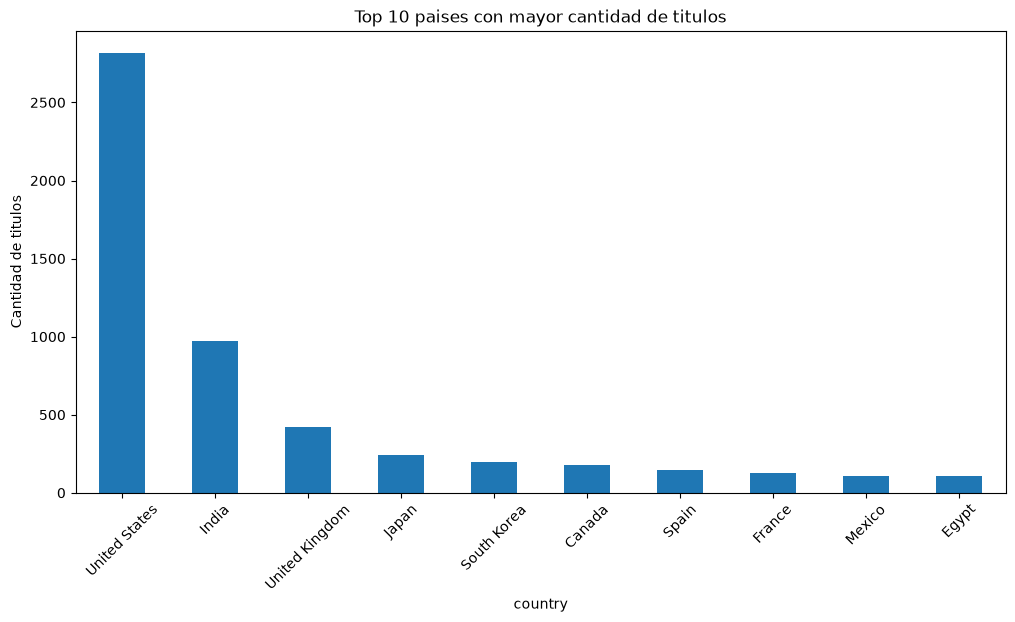

In [130]:
import matplotlib.pyplot as plt

top_10=df.groupby('country')['show_id'].count().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

top_10.plot(kind='bar')

plt.title('Top 10 paises con mayor cantidad de titulos')
plt.xticks(rotation=45)
plt.ylabel('Cantidad de titulos')

plt.show()


### Ejercicio 12 - Genera un gráfico de barras mostrando la cantidad de:

- Movies
- TV Shows

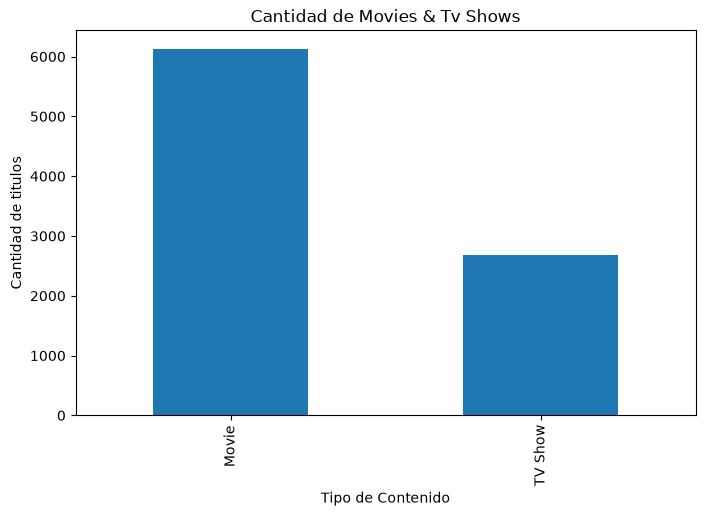

In [135]:
import matplotlib.pyplot as plt

cantidad=df['type'].value_counts()

plt.figure(figsize=(8, 5))

cantidad.plot(kind='bar')

plt.title('Cantidad de Movies & Tv Shows')
plt.xlabel('Tipo de Contenido')
plt.ylabel('Cantidad de titulos')

plt.show()

### Ejercicio 13 - Utilizando la tabla dinámica, crea un gráfico de barras agrupadas que compare películas y series por país.


<Figure size 1000x800 with 0 Axes>

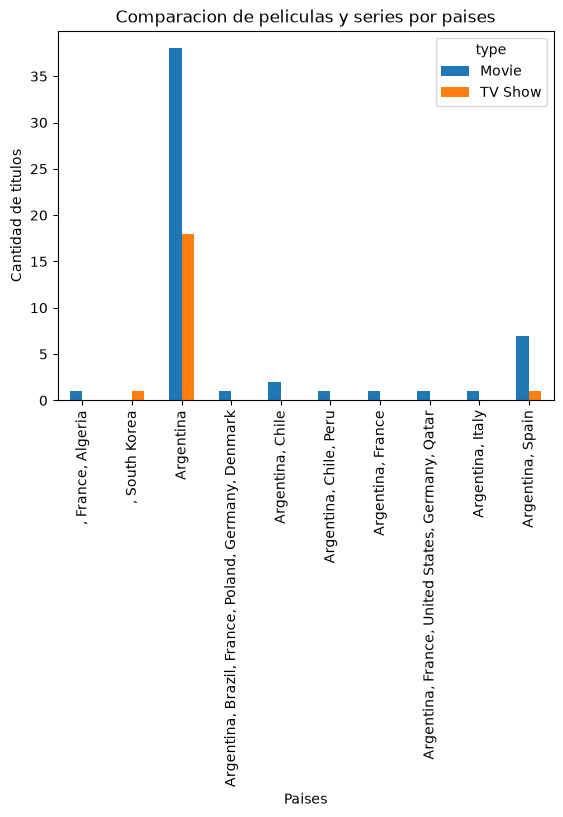

In [161]:
import matplotlib.pyplot as plt


orden_pais= df.pivot_table(
    index='country',
    columns='type',
    values='show_id',
    aggfunc='count',
    fill_value=0
).head(10)


plt.figure(figsize=(10, 8))

orden_pais.plot(kind='bar')


plt.title('Comparacion de peliculas y series por paises')
plt.xlabel('Paises')
plt.ylabel('Cantidad de titulos')

plt.show()



## Parte 6: Análisis

Redacta al menos **cinco insights** basados en el análisis realizado. Algunas preguntas que puedes responder son:

- ¿Qué país domina el catálogo? El pais que domina el catalogo es Estados Unidos
- ¿Netflix posee más películas o más series? Netflix posee mas peliculas que series, cuenta con 6131 peliculas y 2676 series
- ¿Qué clasificación por edades es la más utilizada? La mas utilizadas son TV-MA con 3207 y TV-14 CON 2160
- ¿Existen países donde predominen las series? Si, los paises que mas predominan en las series son Reino Unido (Pelicuas: 206 / Series: 213), Japon (Pelicuas: 76 / Series: 169) y Corea del Sur (Pelicuas: 41 / Series: 158)
- ¿Qué tendencia observas respecto al año de lanzamiento de los contenidos? Se observa una tendencia en crecimiento a partir del año 2000, con un crecimiento mas pronunciado a partir del 2010, llegando a su maximo en 2018 donde se lanzaron 1147 contenidos, donde luego empezo una caida decendiente hasta el 2020

Justifica cada respuesta utilizando los datos obtenidos.

In [ ]:
#Pais dominante
pais_dominante=df.groupby(["country"])["title"].count().sort_values(ascending=False)

#Total de peliculas y series
pelis_series=df.groupby('type')['show_id'].count()

#Edades que son mas utilizadas
edades=df.groupby('rating')['show_id'].count().sort_values(ascending=False)

#Series que predominan mas que las peliculas en el pais
pais_serie=df.groupby(["country", "type"])["show_id"].count().unstack(fill_value=0)
resultado=pais_serie[pais_serie['TV Show']> pais_serie['Movie']]
resultado = resultado.sort_values(by="TV Show", ascending=False)

print(f"Pais que mas domina:\n{pais_dominante.head(1)}")
print()
print(f"Total de peliculas y series de Netflix:\n{pelis_series}")
print()
print(f"Edades que mas se utilizan:\n{edades.head(3)}")
print()
print(f"Paises donde predominan mas las series:\n{resultado.head(4)}")


Pais que mas domina:
country
United States    2818
Name: title, dtype: int64

Total de peliculas y series de Netflix:
type
Movie      6131
TV Show    2676
Name: show_id, dtype: int64

Edades que mas se utilizan:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
Name: show_id, dtype: int64

Paises donde predominan mas las series:
type            Movie  TV Show
country                       
United Kingdom    206      213
Japan              76      169
South Korea        41      158
Taiwan             13       68


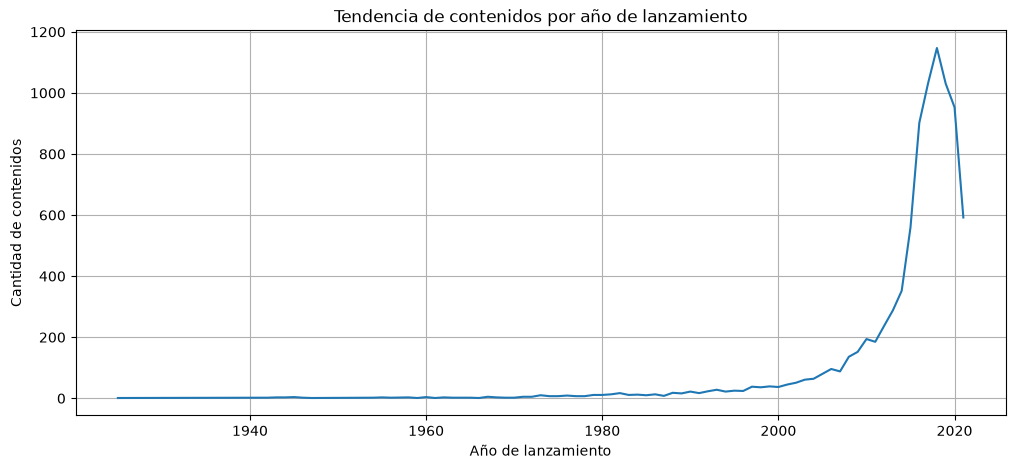

Año con más contenidos: 2018
Cantidad de contenidos: 1147


In [ ]:
#Realizamos un grafico para ver la tendencia respecto al año de lanzamiento de los contenidos

import matplotlib.pyplot as plt


contenidos_por_anio = df["release_year"].value_counts().sort_index()

contenidos_por_anio.plot(kind="line", figsize=(12, 5))

plt.title("Tendencia de contenidos por año de lanzamiento")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Cantidad de contenidos")
plt.grid(True)
plt.show()
print("Año con más contenidos:", contenidos_por_anio.idxmax())
print("Cantidad de contenidos:", contenidos_por_anio.max())

## Desafío

Netflix desea aumentar su presencia en Latinoamérica. Analiza únicamente los siguientes países:

- Argentina
- Brasil
- Chile
- Colombia
- México
- Perú

Responde:

1. ¿Cuál aporta mayor cantidad de contenido?
2. ¿Predominan las películas o las series?
3. ¿Qué clasificación por edades es la más común?
4. Genera un gráfico comparativo.
5. Escribe una breve recomendación para el director regional de Netflix basada en tus resultados.


In [ ]:
# tu código acá